# Preprocessing

In [2]:
import numpy as np
import pandas as pd
from plotnine import *
from pandas.api.types import CategoricalDtype

cbPalette = ["#E69F00", "#56B4E9", "#009E73", 
             "#F0E442", "#0072B2", "#D55E00", 
             "#CC79A7", "#999999"]

In [3]:
mpc_data = pd.read_csv('mpc_results.csv')
tmpc_data = pd.read_csv('tmpc_results.csv')
sddtmpc_data = pd.read_csv('sdd_results.csv')

mpc_data['type'] = 'MPC'
tmpc_data['type'] = 'TMPC'
sddtmpc_data['type'] = 'SDD-TMPC'
data = pd.concat([mpc_data, tmpc_data, sddtmpc_data], ignore_index=True)

order = CategoricalDtype(
    categories=["SDD-TMPC", "TMPC", "MPC"],
    ordered=True
)
data["type"] = data["type"].astype(order)

data

,outcome,victims_found,duration,wall_collisions,victims_collisions,fire_collisions,wait_actions,area_explored,infeasible_states,avg_tube_size,seed,delta,type
0,TIMEOUT,10,300,1,0,0,204,0.653571,0,0.000000,655801578,0.0,MPC
1,SUCCESS,12,155,0,0,0,0,0.961995,0,0.000000,642346533,0.0,MPC
2,SUCCESS,12,162,0,1,0,0,0.971429,0,0.000000,656309562,0.0,MPC
3,SUCCESS,12,132,0,1,0,0,0.869219,0,0.000000,224160443,0.0,MPC
4,SUCCESS,12,116,0,0,0,0,0.868284,0,0.000000,668985370,0.0,MPC
...,...,...,...,...,...,...,...,...,...,...,...,...,...
745,SUCCESS,12,268,0,0,0,35,0.994455,0,0.063433,445649934,0.0,SDD-TMPC
746,SUCCESS,12,179,0,0,0,23,0.982418,0,0.324022,529388546,0.0,SDD-TMPC
747,TIMEOUT,11,300,0,0,0,48,0.955801,0,0.086667,953422941,0.0,SDD-TMPC
748,SUCCESS,12,173,0,0,0,3,0.922131,0,0.595376,992984681,0.0,SDD-TMPC


# Sub-question 1: Mapping

## Collisions

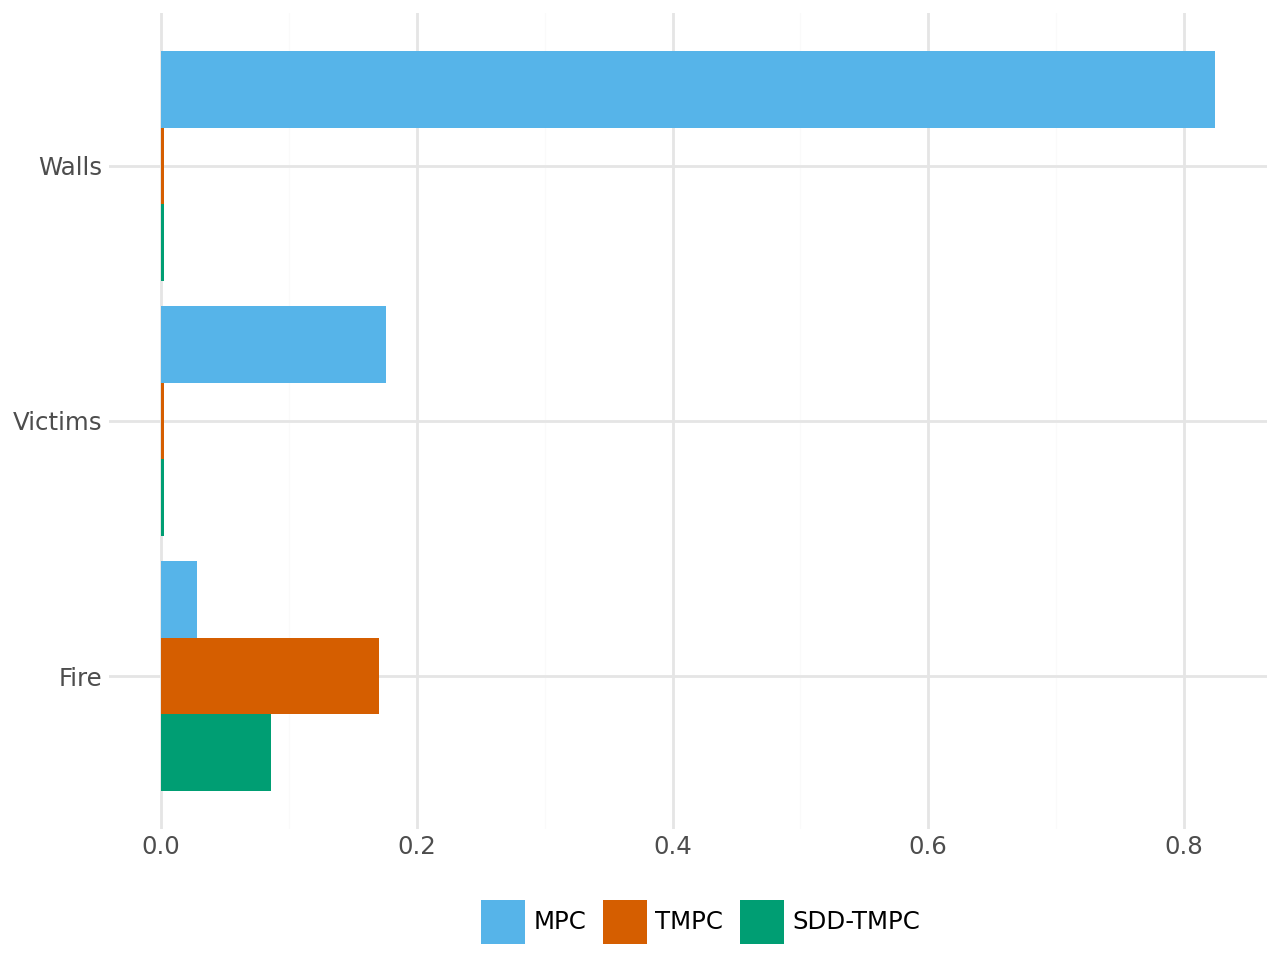

,type,wall_collisions,victims_collisions,fire_collisions
0,SDD-TMPC,0,0,21
1,TMPC,0,0,42
2,MPC,206,44,7


In [4]:
collisions = data[['wall_collisions', 'victims_collisions', 'fire_collisions', 'type']]
collisions = collisions.groupby('type', observed=True).mean().reset_index()
collisions.columns = ['type', 'Walls', 'Victims', 'Fire']
collisions = collisions.melt(id_vars='type', value_vars=['Walls', 'Victims', 'Fire'], var_name='collision_type')

collisions.loc[collisions['type'] == 'TMPC', 'value'] += 0.002 # Make TMPC actually visible
collisions.loc[collisions['type'] == 'SDD-TMPC', 'value'] += 0.002 # Make SDD-TMPC actually visible

(
    ggplot(collisions, aes(x='collision_type', y='value', fill='type')) 
           + geom_col(position='dodge')
           + scale_fill_manual(values=[cbPalette[2], cbPalette[5], cbPalette[1]])
           + guides(fill=guide_legend(reverse=True))
           + labs(x="", y="", fill="")
           + coord_flip()
           + theme_minimal()
           + theme(legend_position="bottom")
).show()

table = data[['wall_collisions', 'victims_collisions', 'fire_collisions', 'type']]
table = table.groupby('type', observed=True).sum().reset_index()
table

## Outcome

### Success Rates

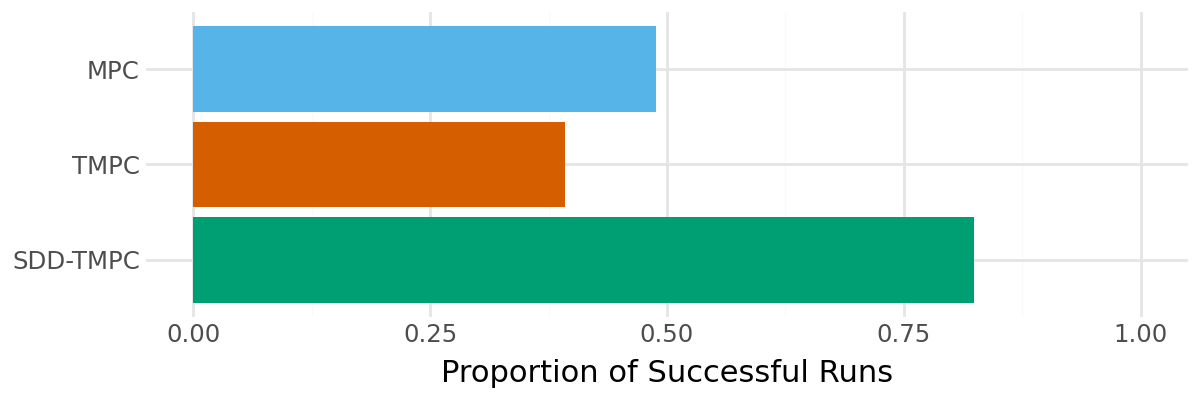

,type,outcome,success_rate
0,SDD-TMPC,206,0.824
1,TMPC,98,0.392
2,MPC,122,0.488


In [5]:
success_rates = data[['outcome', 'type', 'wall_collisions', 'victims_collisions']].copy()
success_rates['wall_collisions'] = success_rates['wall_collisions'].apply(lambda x: 1 if x == 0 else 0)
success_rates['victims_collisions'] = success_rates['victims_collisions'].apply(lambda x: 1 if x == 0 else 0)
success_rates['outcome'] = success_rates['outcome'].apply(lambda x: 1 if x == 'SUCCESS' else 0)
success_rates['outcome'] = success_rates['outcome'] * success_rates['wall_collisions'] * success_rates['victims_collisions']
success_rates = success_rates[['outcome', 'type']].groupby('type', observed=True).sum().reset_index()
success_rates['success_rate'] = success_rates['outcome'] / 250

(
    ggplot(success_rates, aes(x='type', y='success_rate', fill='type'))
        + geom_col()
        + coord_flip()
        + labs(x='', y='Proportion of Successful Runs', fill='')
        + scale_x_discrete(limits=['SDD-TMPC', 'TMPC', 'MPC'])
        + scale_y_continuous(limits=[0, 1])
        + scale_fill_manual(values=[cbPalette[2], cbPalette[5], cbPalette[1]])
        + theme_minimal()
        + theme(legend_position="none", figure_size=(6, 2))
).show()

success_rates

### McNemar Test

In [6]:
from statsmodels.stats.contingency_tables import mcnemar
# McNemar Test
success_nemar = data[['seed', 'outcome', 'type', 'wall_collisions', 'victims_collisions']].copy()
success_nemar['wall_collisions'] = success_nemar['wall_collisions'].apply(lambda x: 1 if x == 0 else 0)
success_nemar['victims_collisions'] = success_nemar['victims_collisions'].apply(lambda x: 1 if x == 0 else 0)
success_nemar['outcome'] = success_nemar['outcome'].apply(lambda x: 1 if x == 'SUCCESS' else 0)
success_nemar['outcome'] = success_nemar['outcome'] * success_nemar['wall_collisions'] * success_nemar['victims_collisions']
success_nemar = success_nemar[['seed', 'outcome', 'type']]
success_nemar = success_nemar[success_nemar['type'] != 'MPC']
success_nemar = success_nemar.pivot(
    index = 'seed',
    columns = 'type',
    values = 'outcome'
)
success_nemar = pd.crosstab(
    success_nemar['TMPC'],
    success_nemar['SDD-TMPC']
)

success_nemar_res = mcnemar(success_nemar, exact=True)
print(f"Statistic: {success_nemar_res.statistic}")
print(f"P-value: {success_nemar_res.pvalue}")

success_nemar

Statistic: 1.0
P-value: 1.7102257906158654e-31


SDD-TMPC,0,1
TMPC,,
0,43,109
1,1,97


### Odds Ratio

In [7]:
odds = data[['seed', 'outcome', 'type', 'wall_collisions', 'fire_collisions']].copy()
odds['wall_collisions'] = odds['wall_collisions'].apply(lambda x: 1 if x == 0 else 0)
odds['fire_collisions'] = odds['fire_collisions'].apply(lambda x: 1 if x == 0 else 0)
odds['outcome'] = odds['outcome'].apply(lambda x: 1 if x == 'SUCCESS' else 0)
odds['outcome'] = odds['outcome'] * odds['wall_collisions'] * odds['fire_collisions']
odds = odds[['seed', 'outcome', 'type']]
odds = odds[odds['type'] != 'MPC'].reset_index(drop=True)
odds = odds.pivot(
    index='seed',
    columns='type',
    values='outcome'
)

a = odds[(odds['TMPC'] == 1) & (odds['SDD-TMPC'] == 1)].shape[0]
b = odds[(odds['TMPC'] == 1) & (odds['SDD-TMPC'] == 0)].shape[0]
c = odds[(odds['TMPC'] == 0) & (odds['SDD-TMPC'] == 1)].shape[0]
d = odds[(odds['TMPC'] == 0) & (odds['SDD-TMPC'] == 0)].shape[0]

odds_ratio = a * d / (b * c)

import numpy as np
log_or = np.log(odds_ratio)
se = np.sqrt(1/a + 1/b + 1/c + 1/d)
ci_low = np.exp(log_or - 1.96 * se)
ci_high = np.exp(log_or + 1.96 * se)

print("Odds ratio:", odds_ratio, "(95% CI: [", ci_low, ", ", ci_high, "])")
print("Contingency Table:")
print(f"           TMPC SUCCESS  TMPC TIMEOUT")
print(f"SDD-SUCCESS     {a}            {c}")
print(f"SDD-TIMEOUT     {b}            {d}")
print(f"Total: {a+b+c+d}")

Odds ratio: 40.0 (95% CI: [ 5.409953916819747 ,  295.75113293027147 ])
Contingency Table:
           TMPC SUCCESS  TMPC TIMEOUT
SDD-SUCCESS     96            108
SDD-TIMEOUT     1            45
Total: 250


## Mission Time

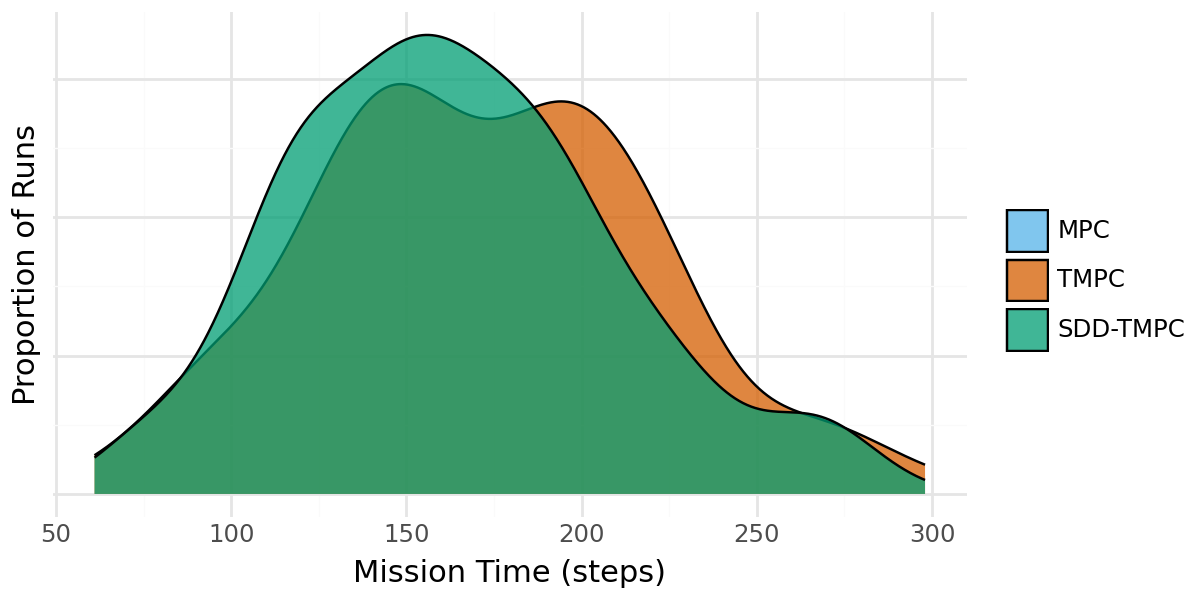

Unsuccessful MPC: 250
Unsuccessful TMPC: 152
Unsuccessful SDD-TMPC: 44


In [8]:
mission_times = data[['seed', 'outcome', 'duration', 'type', 'wall_collisions', 'victims_collisions']]
mission_times = mission_times[mission_times['type'] != 'MPC']
mission_times = mission_times[(mission_times['wall_collisions'] == 0) & (mission_times['victims_collisions'] == 0)]
mission_times = mission_times[mission_times['outcome'] == 'SUCCESS'].reset_index(drop=True)
mission_times = mission_times[['seed', 'type', 'duration']]
order = CategoricalDtype(
    categories=["MPC", "TMPC", "SDD-TMPC"],
    ordered=True
)
mission_times["type"] = mission_times["type"].astype(order)
(
    ggplot(mission_times, aes(x='duration', fill='type'))
    # + geom_density(alpha=0.85, kernel='triw', adjust=1.5)
    + geom_density(alpha=0.75, kernel='gaussian')
    + scale_fill_manual(values=[cbPalette[1], cbPalette[5], cbPalette[2]])
    + scale_y_continuous(breaks=[0, 0.0025, 0.005, 0.0075, 0.01], labels=["", "", "", "", ""])
    # + guides(fill=guide_legend(reverse=True))
    + labs(
        x="Mission Time (steps)",
        y="Proportion of Runs",
        fill=""
    )
    + theme_minimal()
    + theme(figure_size=(6, 3))
).show()
unsuccessful_mpc = 250 - mission_times[mission_times['type'] == 'MPC'].shape[0]
unsuccessful_tmpc = 250 - mission_times[mission_times['type'] == 'TMPC'].shape[0]
unsuccessful_sdd_tmpc = 250 - mission_times[mission_times['type'] == 'SDD-TMPC'].shape[0]
print(f"Unsuccessful MPC: {unsuccessful_mpc}")
print(f"Unsuccessful TMPC: {unsuccessful_tmpc}")
print(f"Unsuccessful SDD-TMPC: {unsuccessful_sdd_tmpc}")

### Wilcoxon

In [9]:
from scipy.stats import wilcoxon

mission_times = data[['seed', 'outcome', 'duration', 'type', 'wall_collisions', 'victims_collisions']]
mission_times = mission_times[mission_times['type'] != 'MPC']
mission_times = mission_times[(mission_times['wall_collisions'] == 0) & (mission_times['victims_collisions'] == 0)]
mission_times = mission_times[mission_times['outcome'] == 'SUCCESS'].reset_index(drop=True)
mission_times = mission_times[['seed', 'type', 'duration']]
mission_times = mission_times.pivot(index='seed', columns='type', values='duration').dropna()

result = wilcoxon(
    mission_times["TMPC"],
    mission_times["SDD-TMPC"],
    alternative='two-sided'
)
print(f"statistic: {result.statistic}")
print(f"p-value: {result.pvalue}")

statistic: 1612.0
p-value: 0.005940734714085402


In [10]:
# Get median mission durations for TMPC and SDD-TMPC
mission_times = data[['seed', 'outcome', 'duration', 'type', 'wall_collisions', 'victims_collisions']]
mission_times = mission_times[mission_times['type'] != 'MPC']
mission_times = mission_times[(mission_times['wall_collisions'] == 0) & (mission_times['victims_collisions'] == 0)]
mission_times = mission_times[mission_times['outcome'] == 'SUCCESS'].reset_index(drop=True)
mission_times = mission_times[['seed', 'type', 'duration']]
mission_times = mission_times.pivot(index='seed', columns='type', values='duration').dropna()
print(f"TMPC: {mission_times['TMPC'].median()}")
print(f"SDD-TMPC: {mission_times['SDD-TMPC'].median()}")

TMPC: 170.0
SDD-TMPC: 153.0


# Sub-question 2: Noise

In [11]:
noise_df = pd.read_csv('noise_results.csv')
sdd_df = pd.read_csv('sdd_results.csv')

# Set noise_df to noise_df appended to sdd_df
noise_df = pd.concat([sdd_df, noise_df], ignore_index=True)
noise_df

,outcome,victims_found,duration,wall_collisions,victims_collisions,fire_collisions,wait_actions,area_explored,infeasible_states,avg_tube_size,seed,delta
0,TIMEOUT,8,300,0,0,0,70,0.887500,0,0.276667,655801578,0.0
1,SUCCESS,12,199,0,0,14,58,0.952494,42,0.512563,642346533,0.0
2,SUCCESS,12,157,0,0,0,1,0.914286,0,0.394904,656309562,0.0
3,SUCCESS,12,199,0,0,0,0,0.993620,0,0.241206,224160443,0.0
4,SUCCESS,12,188,0,0,0,8,0.980936,0,0.329787,668985370,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...
995,TIMEOUT,8,300,0,1,0,69,0.456562,2,0.326667,445649934,0.4
996,SUCCESS,12,198,0,0,0,28,0.967033,0,0.212121,529388546,0.4
997,TIMEOUT,9,300,1,0,0,57,0.841621,1,0.133333,953422941,0.4
998,TIMEOUT,10,300,0,0,0,27,0.860656,0,0.540000,992984681,0.4


## Collisions

In [12]:
# Group by delta, get sum of collisions of each type
noise_collisions = noise_df[['delta', 'wall_collisions', 'victims_collisions', 'fire_collisions']].groupby('delta', observed=True).sum().reset_index()
noise_collisions

,delta,wall_collisions,victims_collisions,fire_collisions
0,0.0,0,0,21
1,0.1,0,0,7
2,0.2,0,0,7
3,0.4,5,4,39


### McNemar

In [13]:
# McNemar on collisions between delta 0.2 and 0.4
nemar_df = noise_df[(noise_df['delta'] == 0.2) | (noise_df['delta'] == 0.4)]
nemar_df = nemar_df[['seed', 'delta', 'outcome', 'wall_collisions', 'victims_collisions']].copy()
nemar_df['collision'] = (nemar_df['wall_collisions'] > 0) | (nemar_df['victims_collisions'] > 0)
wall_q = nemar_df.pivot(
    index = "seed",
    columns = "delta",
    values = "collision"
)
table_wall = pd.crosstab(wall_q[0.2], wall_q[0.4])

result_wall = mcnemar(table_wall, exact=True)
print(f"statistic: {result_wall.statistic}")
print(f"p-value: {result_wall.pvalue}")

table_wall

statistic: 0.0
p-value: 0.00390625


0.4,False,True
0.2,,
False,241,9


## Success Rate

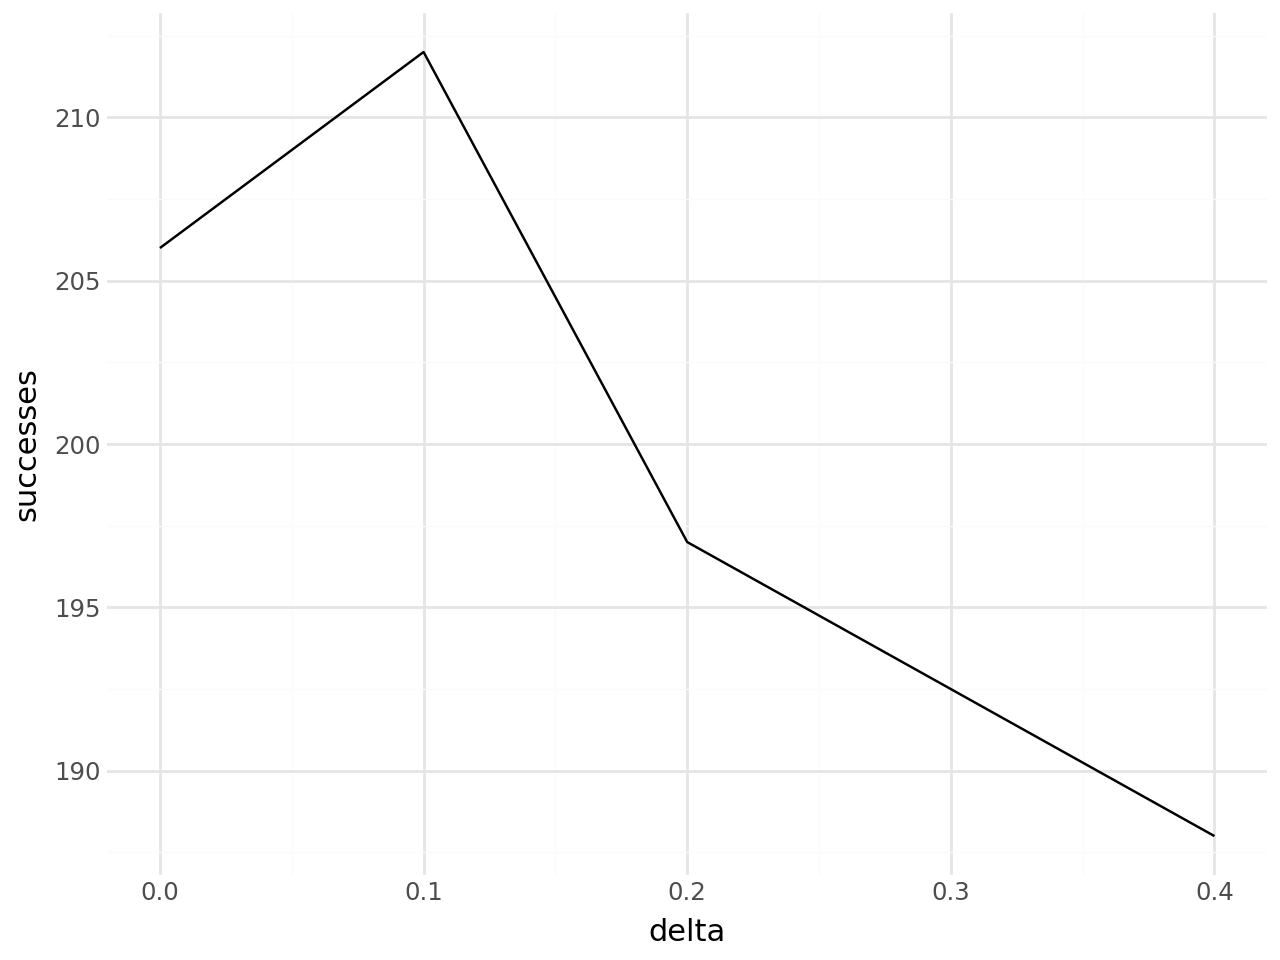

,delta,outcome,success_rate
0,0.0,206,0.824
1,0.1,212,0.848
2,0.2,197,0.788
3,0.4,188,0.752


In [14]:
noise_success = noise_df[['delta', 'outcome', 'wall_collisions', 'victims_collisions']].copy()
noise_success['outcome'] = noise_success['outcome'].apply(lambda x: 1 if x == 'SUCCESS' else 0)
noise_success['wall_collisions'] = noise_success['wall_collisions'].apply(lambda x: 1 if x == 0 else 0)
noise_success['victims_collisions'] = noise_success['victims_collisions'].apply(lambda x: 1 if x == 0 else 0)
noise_success['outcome'] = noise_success['outcome'] * noise_success['wall_collisions'] * noise_success['victims_collisions']
noise_success = noise_success.groupby('delta', observed=True).sum().reset_index()[['delta', 'outcome']]
noise_success['success_rate'] = noise_success['outcome'] / 250

(
    ggplot(noise_success, aes(x="delta", y="outcome"))
    + geom_line()
    + labs(y="successes")
    + theme_minimal()
).show()

noise_success
# If wanting safety guarantee, noise=0.1 not ok, if under probabilistic constraints maybe noise=0.1 it okay?

### Cochran Q

In [15]:
from statsmodels.stats.contingency_tables import cochrans_q

noise_cochran = noise_df[['seed', 'delta', 'outcome', 'wall_collisions', 'victims_collisions']].copy()
noise_cochran['outcome'] = noise_cochran['outcome'].apply(lambda x: 1 if x == 'SUCCESS' else 0)
noise_cochran['wall_collisions'] = noise_cochran['wall_collisions'].apply(lambda x: 1 if x == 0 else 0)
noise_cochran['victims_collisions'] = noise_cochran['victims_collisions'].apply(lambda x: 1 if x == 0 else 0)
noise_cochran['outcome'] = noise_cochran['outcome'] * noise_cochran['wall_collisions'] * noise_cochran['victims_collisions']
noise_cochran = noise_cochran[['seed','delta', 'outcome']]
noise_cochran = noise_cochran[noise_cochran['delta'] != 0.0]
noise_cochran = noise_cochran.pivot(
    index = 'seed',
    columns = 'delta',
    values = 'outcome'
)

noise_cochran_res = cochrans_q(noise_cochran)
print(noise_cochran_res)

df          2
pvalue      0.0030195979700789193
statistic   11.605263157894736


### Odds Ratio

In [16]:
results = {}

for delta_val in [0.1, 0.2, 0.4]:
    odds = noise_df[['seed', 'outcome', 'delta', 'wall_collisions', 'victims_collisions']].copy()
    odds = odds[odds['delta'] == delta_val].copy()
    odds['outcome'] = odds['outcome'].apply(lambda x: 1 if x == 'SUCCESS' else 0)
    odds['wall_collisions'] = odds['wall_collisions'].apply(lambda x: 1 if x == 0 else 0)
    odds['victims_collisions'] = odds['victims_collisions'].apply(lambda x: 1 if x == 0 else 0)
    odds['outcome'] = odds['outcome'] * odds['wall_collisions'] * odds['victims_collisions']
    odds = odds[['seed', 'outcome']]
    
    tmpc_odds = data[data['type'] == 'TMPC'][['seed', 'outcome']].copy()
    tmpc_odds['outcome'] = tmpc_odds['outcome'].apply(lambda x: 1 if x == 'SUCCESS' else 0)
    
    merged = odds.merge(tmpc_odds, on='seed', suffixes=('_sdd', '_tmpc'))
    assert merged.shape[0] == 250, f"Seed mismatch: {merged.shape[0]} rows"

    a = ((merged['outcome_tmpc'] == 1) & (merged['outcome_sdd'] == 1)).sum()
    b = ((merged['outcome_tmpc'] == 1) & (merged['outcome_sdd'] == 0)).sum()
    c = ((merged['outcome_tmpc'] == 0) & (merged['outcome_sdd'] == 1)).sum()
    d = ((merged['outcome_tmpc'] == 0) & (merged['outcome_sdd'] == 0)).sum()
    
    or_val = (a * d) / (b * c)
    
    # 95% CI via log method
    import numpy as np
    log_or = np.log(or_val)
    se = np.sqrt(1/a + 1/b + 1/c + 1/d)
    ci_low = np.exp(log_or - 1.96 * se)
    ci_high = np.exp(log_or + 1.96 * se)
    
    results[delta_val] = {
        'a': a, 'b': b, 'c': c, 'd': d,
        'OR': or_val,
        'CI': (ci_low, ci_high)
    }
    
    print(f"\ndelta={delta_val}")
    print(f"                TMPC SUCCESS  TMPC TIMEOUT")
    print(f"SDD SUCCESS     {a}            {c}")
    print(f"SDD TIMEOUT     {b}            {d}")
    print(f"OR: {or_val:.3f} (95% CI [{ci_low:.3f}, {ci_high:.3f}])")


delta=0.1
                TMPC SUCCESS  TMPC TIMEOUT
SDD SUCCESS     89            123
SDD TIMEOUT     9            29
OR: 2.332 (95% CI [1.052, 5.168])

delta=0.2
                TMPC SUCCESS  TMPC TIMEOUT
SDD SUCCESS     87            110
SDD TIMEOUT     11            42
OR: 3.020 (95% CI [1.469, 6.210])

delta=0.4
                TMPC SUCCESS  TMPC TIMEOUT
SDD SUCCESS     77            111
SDD TIMEOUT     21            41
OR: 1.354 (95% CI [0.743, 2.470])


# Sub-question 3: Conservativeness

206


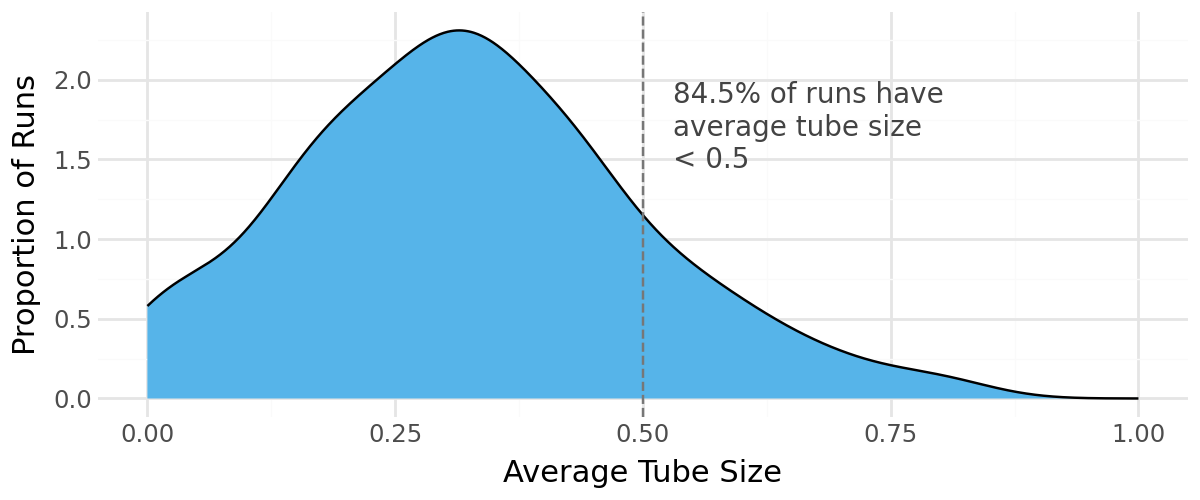

Overall average: 0.32292449564519987


In [20]:
cons_data = data[data['type'] == 'SDD-TMPC']
# Remove infeasible scenarios
cons_data = cons_data[cons_data['wall_collisions'] == 0]
cons_data = cons_data[cons_data['victims_collisions'] == 0]
cons_data = cons_data[cons_data['outcome'] == 'SUCCESS'].reset_index(drop=True)
print(cons_data.shape[0])
cons_data = cons_data[["seed", "avg_tube_size"]]

# # Histogram of conservativeness
# (
#     ggplot(cons_data, aes(x='avg_tube_size'))
#     + geom_histogram(bins=30, binwidth=0.02)
#     + labs(x='Average Tube Size', y='Number of Runs')
#     + theme_minimal()
#     + theme(figure_size=(6, 3))
# )

# Prepare data and make density plot
cons_data['type'] = 'SDD-TMPC'
num_sub_half = cons_data[cons_data['avg_tube_size'] < 0.5].shape[0]
perc_sub_half = round(num_sub_half / cons_data.shape[0], 3) * 100

(
    ggplot(cons_data, aes(x='avg_tube_size', fill='type'))
    + geom_density(kernel='gaussian', position='identity', alpha=1)
    + geom_vline(xintercept=0.5, linetype='dashed', color='#777777')
    + annotate(geom="text", x=0.53, y=1.7, color='#434343', size=10, label=f"{perc_sub_half}% of runs have\naverage tube size\n< {0.5}", ha="left")
    + scale_fill_manual(values=[cbPalette[1]])
    + scale_x_continuous(breaks=[0, 0.25, 0.5, 0.75, 1], limits=[0, 1])
    # + scale_y_continuous(breaks=[0,1,2], labels=["", "", ""])
    + labs(x='Average Tube Size', y='Proportion of Runs')
    + theme_minimal()
    + theme(legend_position="none", figure_size=(6, 2.5))
).show()
print(f"Overall average: {cons_data['avg_tube_size'].mean()}")

## Bootstrap CI

In [18]:
import numpy as np

tube_sizes = cons_data['avg_tube_size'].values

bootstrap_means = [
    np.mean(np.random.choice(tube_sizes, size=len(tube_sizes), replace=True))
    for _ in range(10_000)
]
ci_low, ci_high = np.percentile(bootstrap_means, [2.5, 97.5])
print(f"Mean: {np.mean(tube_sizes):.3f}, 95% CI [{ci_low:.3f}, {ci_high:.3f}]")

Mean: 0.323, 95% CI [0.300, 0.347]
